# Single-Trace Attack on Falcon-512

The attacker has power traces of the victim device and a set of **templates** - one per
possible coefficient value. Goal: recover the secret key `f, g`.

This is a **profiled per-coefficient attack**: profile one coefficient of the decode over all
its values, and - because the decode is a constant-time loop - apply that template to every
coefficient. The attacked `f` is a **real captured secret** (the one in the trace below); `g`
and the public key `h` are generated to form a valid key (they were not measured).

Templates are already trained; we only run the attack.


In [1]:
import os, sys, random
import numpy as np
import matplotlib.pyplot as plt
import trsfile
sys.path.insert(0, os.path.abspath(os.path.join('..', 'template_attack')))
import falcon_keymath as km
n = 512                               # Falcon-512

# trained templates: one model per possible coefficient value
T = np.load(os.path.join('..', 'template_attack', 'templates.npz'))
candidates = T['classes'] - 10; pois = T['pois']
mu, sd, W, b = T['mu'], T['sd'], T['W_lda'], T['b_lda']

# the victim key: real f (from the trace), generated g and public h
K = np.load('nb_falcon512.npz')
f_true = K['f'].astype(int); g_true = K['g'].astype(int); h = K['h'].astype(np.uint32)
example = K['example'].astype(float)

# real power traces, grouped by the coefficient value they measured
traces = {}
with trsfile.trs_open(r'C:/Users/mervkara/Inspector/data/falcon_gui_split_leak1/split_TEST.trs', 'r') as ts:
    for i in range(len(ts)):
        value = int(ts[i].parameters['f0_class'].value[0]) - 10
        traces.setdefault(value, []).append(np.asarray(ts[i].samples)[pois])
for value in traces:
    traces[value] = np.array(traces[value], float)
print('templates for', len(candidates), 'values; victim traces loaded')


templates for 21 values; victim traces loaded


## 1. The victim power trace


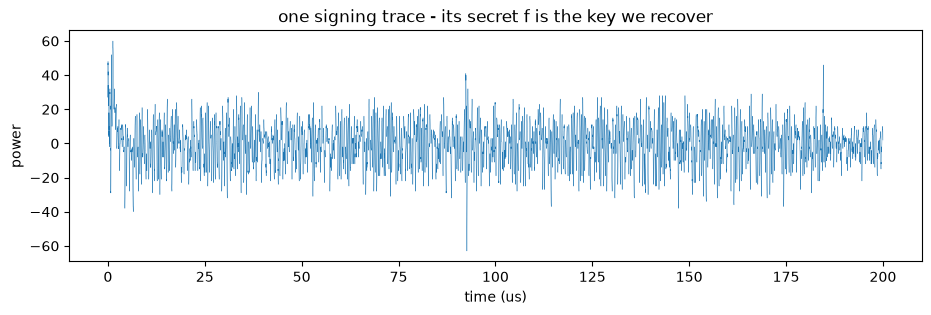

In [2]:
plt.figure(figsize=(11, 3))
plt.plot(np.arange(len(example)) / 1000.0, example, lw=.3)
plt.xlabel('time (us)'); plt.ylabel('power'); plt.title('one signing trace - its secret f is the key we recover')
plt.show()


## 1b. The decode is a periodic loop

The decode runs the same code for every coefficient, so the signal is **periodic**. Sliding
the trace against itself (autocorrelation) it lines back up every ~373 samples:


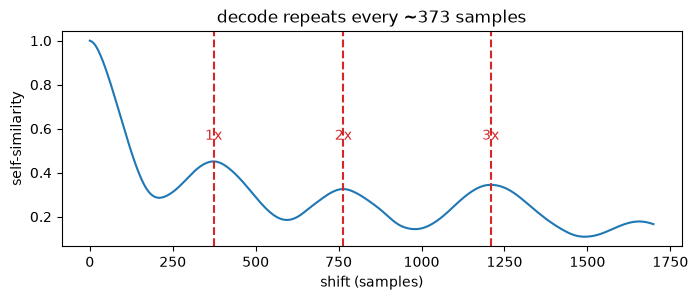

In [3]:
seg = example[:8000] - example[:8000].mean()
ac = np.correlate(seg, seg, 'full')[len(seg) - 1:]; ac = ac / ac[0]
peaks = [k for k in range(100, 1600) if ac[k] > 0.25 and ac[k] >= ac[k-1] and ac[k] >= ac[k+1]]
plt.figure(figsize=(8, 2.8)); plt.plot(ac[:1700])
for m, k in enumerate(peaks, start=1):
    plt.axvline(k, color='C3', ls='--'); plt.text(k, 0.55, f'{m}x', color='C3', ha='center')
plt.xlabel('shift (samples)'); plt.ylabel('self-similarity')
plt.title(f'decode repeats every ~{peaks[0]} samples'); plt.show()


In a **full-key capture** each coefficient would be read at its own offset in one trace. In
**this** dataset every trace is an `f[0]` measurement, so we read each coefficient by matching
its value to the measured traces of that value (next).


## 2. Attack one coefficient

Each coefficient is measured a few times (here 45 traces) and **averaged** to cut the noise.
We score that trace against every template and rank the candidate values. The best is the
prediction; the gap to the runner-up is the confidence.


In [4]:
random.seed(0)
def measure(value, k=45):
    # average k real traces of a coefficient with this value
    if value not in traces or len(traces[value]) < k:
        return None                       # value outside the templates' range
    return np.mean(random.sample(list(traces[value]), k), axis=0)

def scores(trace):
    return ((trace - mu) / sd) @ W.T + b   # one score per candidate value

print(f'attacking f[0]   (true secret value = {f_true[0]:+d})\n')
s = scores(measure(f_true[0])); order = np.argsort(s)[::-1]
print('candidate  score')
for j in order[:5]:
    print(f'  {candidates[j]:+d}   {s[j]:8.2f}')
print(f'\npredicted f[0] = {candidates[order[0]]:+d}   (true {f_true[0]:+d})   confidence {s[order[0]] - s[order[1]]:.2f}')


attacking f[0]   (true secret value = -9)

candidate  score
  -9      64.19
  -10      59.48
  -7      58.67
  -6      55.22
  -8      52.22

predicted f[0] = -9   (true -9)   confidence 4.71


## 3. A few more coefficients


In [5]:
for i in range(10):
    s = scores(measure(f_true[i])); o = np.argsort(s)[::-1]
    print(f'f[{i:>2}]  predicted {candidates[o[0]]:+d}   (secret {f_true[i]:+d})   confidence {s[o[0]] - s[o[1]]:.2f}')


f[ 0]  predicted -9   (secret -9)   confidence 4.76
f[ 1]  predicted -4   (secret -4)   confidence 2.75
f[ 2]  predicted +5   (secret +5)   confidence 0.20
f[ 3]  predicted -8   (secret -8)   confidence 4.30
f[ 4]  predicted -4   (secret -4)   confidence 2.77
f[ 5]  predicted -3   (secret -3)   confidence 0.33
f[ 6]  predicted +5   (secret +5)   confidence 0.09
f[ 7]  predicted -4   (secret -4)   confidence 2.18
f[ 8]  predicted -4   (secret -4)   confidence 3.16
f[ 9]  predicted -4   (secret -4)   confidence 2.62


## 4. Recover the full key

The template reads every coefficient of `f` and `g`. A few values fall outside the templates'
range - those stay unknown. We keep the 520 most-confident reads and solve the public relation
`H*f = g (mod 12289)` for the rest (`n = 512`, so 512 equations pin the 1024 unknowns).

**Check:** every Falcon-512 coefficient must lie in **[-31, 31]**. If the solved key stays in
range it is correct; if not, a trusted read was wrong, so we re-read and retry.


In [6]:
def recover():
    reads = []
    for name, key in (('f', f_true), ('g', g_true)):
        for i in range(n):
            trace = measure(key[i])
            if trace is None:
                continue                   # out of template range -> solved by completion
            s = scores(trace); o = np.argsort(s)[::-1]
            reads.append((s[o[0]] - s[o[1]], name, i, int(candidates[o[0]])))
    reads.sort(reverse=True)
    known_f = {i: v for conf, name, i, v in reads[:520] if name == 'f'}
    known_g = {i: v for conf, name, i, v in reads[:520] if name == 'g'}
    f_full, g_full = km.solve_completion_fast(h, known_f, known_g, n=n)
    f_rec = np.array([km.to_signed(v) for v in f_full])
    g_rec = np.array([km.to_signed(v) for v in g_full])
    return f_rec, g_rec

random.seed(0)
for attempt in range(1, 6):
    f_rec, g_rec = recover()
    in_range = bool(np.all(np.abs(f_rec) <= 31) and np.all(np.abs(g_rec) <= 31))
    print(f'attempt {attempt}: coefficients in [-31, 31]? {in_range}')
    if in_range:
        break
    print('   a kept read was wrong - re-reading and retrying')

np.set_printoptions(threshold=np.inf, linewidth=120)
print('\nrecovered f (all', len(f_rec), 'coefficients):'); print(f_rec)
print('\nsecret key recovered :', np.array_equal(f_rec, f_true) and np.array_equal(g_rec, g_true))


attempt 1: coefficients in [-31, 31]? True

recovered f (all 512 coefficients):
[ -9  -4   5  -8  -4  -3   5  -4  -4  -4   4  -2  -6   5   4   1   0   4  -2  -3   3  -7   4   0   0  -2   1   1   7
   4  -5  -1  -2   4   1  -4   0   2  -1   2  -4   3  -4   1   3   1   8   3   3  -7  -2   0   1  -2   3   5  -4   6
  -3  -4   5  -1   0   0   4  -5   0  -3   2  -1   5  -1  -4  -8  -3   3  -1  -6  -3  -1   1  -2  -4  -2  -2   3  -1
  -3  -7  -3  -4   6  -1   5   2   1   3   2   0   2  -2  -1   0   1  -3  -4   4   1   0  -8   1  -1  -1  -3  -2   0
   5  -1   5   2  -3  -1   0   4  -3 -10  -5   4  -3   8   4   4   6  -5  -1   2  -2   0  -4   7   6  -2   1   0  -1
   3   1  -1   2  -7   0   1  -4   2   5  -2   1   0  -7  -2   0   7  -2  -4  -9   2  -1  -2   2   0   3  -2  -4  -5
  -1   5  -5  -5  -4  -1   4  -6  -2   8  -2   2  -5  -7   0   0  -3   1   2   5  -1   9  -4  -1  -1   7  -8   0   5
   7  -3  -3  -6   4  -1  -9  -2   4   0   3   3   2  -1  -2   9   0   0   0   3  -8   3   1   0   6 